In [1]:
from pathlib import Path

from huggingface_hub import snapshot_download

grand_tour_folder = Path("/datahome/lmertens/grand_tour_dataset")


allow_patterns = ["*/anymal_command_twist.tar", "*/stim320_imu.tar", "*/.zgroup"]


dry_run_file_info = snapshot_download(
    repo_id="leggedrobotics/grand_tour_dataset",
    allow_patterns=allow_patterns,
    # ignore_patterns=ignore_patterns,
    repo_type="dataset",
    dry_run=True,
)

# for file_info in dry_run_file_info:
#     print(f"{file_info.filename} - {file_info.is_cached=}, {file_info.will_download=}")


newly_downloaded_size = sum(
    file_info.file_size for file_info in dry_run_file_info if file_info.will_download
)
total_size = sum(file_info.file_size for file_info in dry_run_file_info)
total_num_files = len(dry_run_file_info)

print(f"Total size of files to be downloaded: {newly_downloaded_size / (1e6):.2f} MB")
print(f"Total size of all files (including cached): {total_size / (1e6):.2f} MB")
print(f"Total number of files: {total_num_files}")


[dry-run] Fetching ... files: 0it [00:00, ?it/s]

Total size of files to be downloaded: 934.06 MB
Total size of all files (including cached): 954.11 MB
Total number of files: 144


In [ ]:
from shared_utils import move_dataset

dataset_folder = Path("/datahome/lmertens/grand_tour_dataset")
dataset_folder.mkdir(parents=True, exist_ok=True)


print("Downloading dataset from Hugging Face Hub...")


hugging_face_data_cache_path = snapshot_download(
    repo_id="leggedrobotics/grand_tour_dataset",
    allow_patterns=allow_patterns,
    # ignore_patterns=ignore_patterns,
    repo_type="dataset",
)


move_dataset(
    hugging_face_data_cache_path, dataset_folder, allow_patterns=allow_patterns
)

Start moving from /home/lmertens/.cache/huggingface/hub/datasets--leggedrobotics--grand_tour_dataset/snapshots/daf91c5e2b6db564822a35cc58222d73f8e75bab to /datahome/lmertens/grand_tour_dataset_sidestepping_experiment !
Moved data from /home/lmertens/.cache/huggingface/hub/datasets--leggedrobotics--grand_tour_dataset/snapshots/daf91c5e2b6db564822a35cc58222d73f8e75bab to /datahome/lmertens/grand_tour_dataset_sidestepping_experiment !


/home/lmertens/git-repos/ma-lucamertens/.venv/lib/python3.11/site-packages/numcodecs/__init__.py:106: DeprecationWarning: crc32c usage is deprecated since numcodecs v0.16.4. It is recommended to install google_crc32c instead.
  from numcodecs.checksum32 import CRC32, Adler32, JenkinsLookup3


Processed 48 missions.


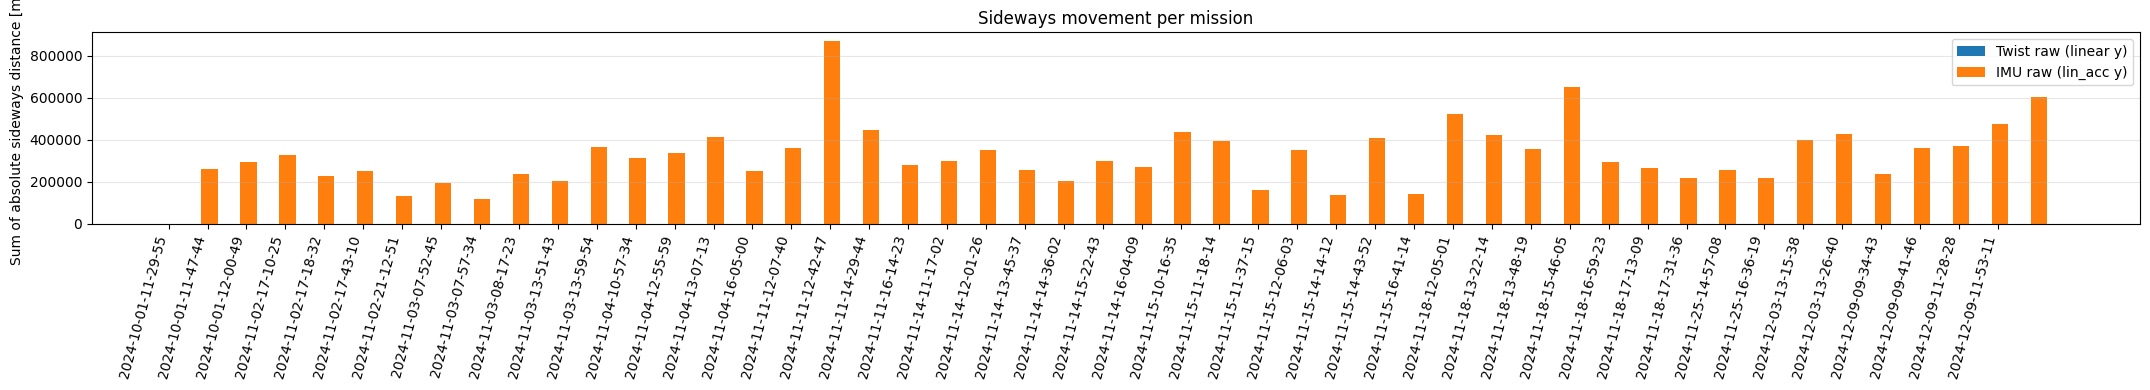

2024-10-01-11-29-55: twist=6.62 m, imu=2369.98 m
2024-10-01-11-47-44: twist=23.31 m, imu=5327.52 m
2024-10-01-12-00-49: twist=20.95 m, imu=3275.83 m
2024-11-02-17-10-25: twist=0.44 m, imu=608.80 m
2024-11-02-17-18-32: twist=0.04 m, imu=3072.11 m
2024-11-02-17-43-10: twist=8.11 m, imu=339.39 m
2024-11-02-21-12-51: twist=0.00 m, imu=3937.54 m
2024-11-03-07-52-45: twist=0.00 m, imu=1723.59 m
2024-11-03-07-57-34: twist=0.00 m, imu=1434.18 m
2024-11-03-08-17-23: twist=0.00 m, imu=1453.41 m
2024-11-03-13-51-43: twist=0.05 m, imu=11385.49 m
2024-11-03-13-59-54: twist=0.00 m, imu=11681.35 m
2024-11-04-10-57-34: twist=2.27 m, imu=24716.71 m
2024-11-04-12-55-59: twist=0.00 m, imu=36780.43 m
2024-11-04-13-07-13: twist=0.00 m, imu=20350.76 m
2024-11-04-16-05-00: twist=0.05 m, imu=8236.13 m
2024-11-11-12-07-40: twist=0.84 m, imu=61051.64 m
2024-11-11-12-42-47: twist=0.05 m, imu=9449.51 m
2024-11-11-14-29-44: twist=0.22 m, imu=3457.49 m
2024-11-11-16-14-23: twist=5.93 m, imu=9447.14 m
2024-11-14-11-

In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import zarr


def _seconds(t):
    t = np.asarray(t, dtype=float)
    return t / 1e9 if np.nanmax(np.abs(t)) > 1e12 else t


def _abs_distance_from_velocity(v, t):
    return float(np.trapezoid(np.abs(v), t))


def _abs_distance_from_acceleration(a, t):
    dt = np.diff(t, prepend=t[0])
    v = np.cumsum((a - np.median(a)) * dt)
    return float(np.sum(np.abs(v) * dt))


dataset_root = globals().get(
    "dataset_folder",
    Path("/datahome/lmertens/grand_tour_dataset"),
)
mission_data_dirs = sorted(p for p in dataset_root.glob("*/data") if p.is_dir())
results = []

for data_dir in mission_data_dirs:
    t_twist = _seconds(
        zarr.open_array(data_dir / "anymal_command_twist" / "timestamp", mode="r")[:]
    )
    v_lat = np.asarray(
        zarr.open_array(data_dir / "anymal_command_twist" / "linear", mode="r")[:, 1],
        dtype=float,
    )

    t_imu = _seconds(
        zarr.open_array(data_dir / "stim320_imu" / "timestamp", mode="r")[:]
    )
    a_lat = np.asarray(
        zarr.open_array(data_dir / "stim320_imu" / "lin_acc", mode="r")[:, 1],
        dtype=float,
    )

    results.append({
        "mission": data_dir.parent.name,
        "twist_abs_sum_of_raw_v": float(np.sum(np.abs(v_lat))),
        "twist_abs_distance_m": _abs_distance_from_velocity(v_lat, t_twist),
        "imu_abs_sum_of_raw_a": float(np.sum(np.abs(a_lat))),
        "imu_abs_distance_m": _abs_distance_from_acceleration(a_lat, t_imu),
    })

results = sorted(results, key=lambda r: r["mission"])
print(f"Processed {len(results)} missions.")
missions = [r["mission"] for r in results]
twist_vals = [r["twist_abs_distance_m"] for r in results]
twist_raw_vals = [r["twist_abs_sum_of_raw_v"] for r in results]
imu_vals = [r["imu_abs_distance_m"] for r in results]
imu_raw_vals = [r["imu_abs_sum_of_raw_a"] for r in results]

x = np.arange(len(missions))
w = 0.42
fig, ax = plt.subplots(figsize=(max(10, 0.45 * len(missions)), 4))
# ax.bar(x - w / 2, twist_vals, width=w, label="Twist (linear y)")
# ax.bar(x + w / 2, imu_vals, width=w, label="IMU (lin_acc y, integrated)")
ax.bar(x + w * 1.5, twist_raw_vals, width=w, label="Twist raw (linear y)")
ax.bar(x + w * 2.5, imu_raw_vals, width=w, label="IMU raw (lin_acc y)")
ax.set_ylabel("Sum of absolute sideways distance [m]")
ax.set_title("Sideways movement per mission")
ax.set_xticks(x, missions, rotation=75, ha="right")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

for r in results:
    print(
        f"{r['mission']}: twist={r['twist_abs_distance_m']:.2f} m, imu={r['imu_abs_distance_m']:.2f} m"
    )

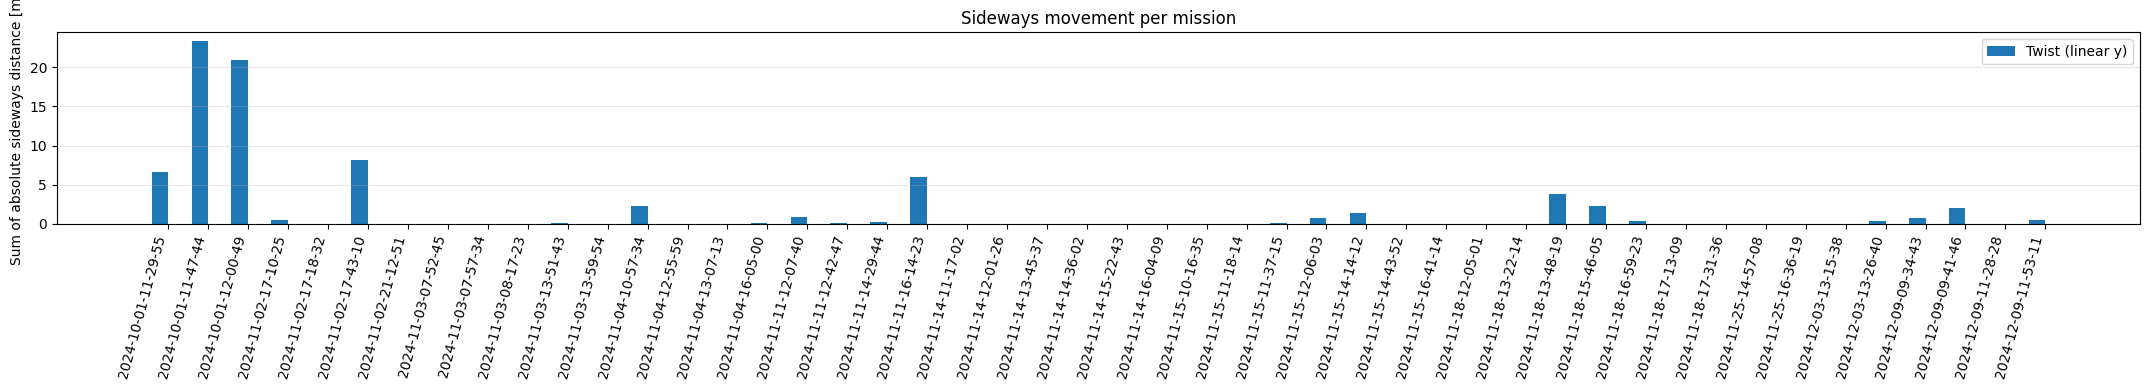

In [4]:
fig, ax = plt.subplots(figsize=(max(10, 0.45 * len(missions)), 4))
ax.bar(x - w / 2, twist_vals, width=w, label="Twist (linear y)")
# ax.bar(x + w / 2, imu_vals, width=w, label="IMU (lin_acc y, integrated with ZUPT)")
ax.set_ylabel("Sum of absolute sideways distance [m]")
ax.set_title("Sideways movement per mission")
ax.set_xticks(x, missions, rotation=75, ha="right")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Encoding MP4:   0%|          | 0/6189 [00:00<?, ?frame/s]

In [4]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import zarr
from matplotlib.backends.backend_pdf import PdfPages


def _seconds(t):
    t = np.asarray(t, dtype=float)
    return t / 1e9 if np.nanmax(np.abs(t)) > 1e12 else t


def _break_on_large_time_gaps(t, y, gap_factor=8.0, min_gap_s=0.5):
    t = np.asarray(t, dtype=float)
    y = np.asarray(y, dtype=float)
    if t.size < 3:
        return t, y

    dt = np.diff(t)
    typical_dt = np.median(dt[dt > 0]) if np.any(dt > 0) else 0.0
    gap_threshold = max(min_gap_s, gap_factor * typical_dt)
    gap_idx = np.where(dt > gap_threshold)[0]

    if gap_idx.size == 0:
        return t, y

    # Insert NaN after each large gap so Matplotlib renders disconnected segments.
    t_plot = np.insert(t, gap_idx + 1, np.nan)
    y_plot = np.insert(y, gap_idx + 1, np.nan)
    return t_plot, y_plot


dataset_root = Path("/datahome/lmertens/grand_tour_dataset")
mission_data_dirs = sorted(p for p in dataset_root.glob("*/data") if p.is_dir())

# Saving plots to disk keeps notebook outputs small and save-friendly.
output_dir = Path(
    "/home/lmertens/git-repos/ma-lucamertens/side_experiments/results/twist_magnitude_plots"
)
output_dir.mkdir(parents=True, exist_ok=True)
pdf_path = output_dir / "all_missions_twist_magnitudes.pdf"

show_inline = False  # Set True only if you want to preview plots in notebook.
save_png = True
save_pdf = True

num_plots = 0
pdf = PdfPages(pdf_path) if save_pdf else None

try:
    for data_dir in mission_data_dirs:
        twist_dir = data_dir / "anymal_command_twist"
        if not twist_dir.exists():
            continue

        t = _seconds(zarr.open_array(twist_dir / "timestamp", mode="r")[:])
        v = np.asarray(zarr.open_array(twist_dir / "linear", mode="r")[:], dtype=float)

        vx_mag = np.abs(v[:, 0])
        vy_mag = np.abs(v[:, 1])

        t_x, vx_plot = _break_on_large_time_gaps(t, vx_mag)
        t_y, vy_plot = _break_on_large_time_gaps(t, vy_mag)

        fig, ax = plt.subplots(figsize=(10, 3.8))
        ax.plot(t_x, vx_plot, label="|v_x|", lw=1.1)
        ax.plot(t_y, vy_plot, label="|v_y|", lw=1.1)
        ax.set_title(f"{data_dir.parent.name}: linear velocity command magnitudes")
        ax.set_xlabel("time [s]")
        ax.set_ylabel("magnitude [m/s]")
        ax.grid(alpha=0.3)
        ax.legend()
        fig.tight_layout()

        if save_png:
            fig.savefig(
                output_dir / f"{data_dir.parent.name}_twist_magnitudes.png",
                dpi=140,
                bbox_inches="tight",
            )

        if pdf is not None:
            pdf.savefig(fig)

        if show_inline:
            plt.show()
        else:
            plt.close(fig)

        num_plots += 1
finally:
    if pdf is not None:
        pdf.close()

print(f"Created {num_plots} plots in: {output_dir}")
if save_pdf:
    print(f"Combined PDF: {pdf_path}")

Created 48 plots in: /home/lmertens/git-repos/ma-lucamertens/side_experiments/results/twist_magnitude_plots
Combined PDF: /home/lmertens/git-repos/ma-lucamertens/side_experiments/results/twist_magnitude_plots/all_missions_twist_magnitudes.pdf
